# Phase 2: Build the free dataset collection

| Dataset | Period | Purpose |
|---|---|---|
| MODIS MOD11A2 v6.1 | 2001-2025 | Main LST time series |
| Landsat 8/9 | selected years from 2013 | Detailed temperature maps; reflectance for NDVI, NDBI, NDWI |
| ESA WorldCover | 2020, 2021 | Land-cover classification |
| ERA5-Land | 2001-2025 | Weather variables |

Steps: (1-2) MODIS daytime LST + QC for both cities; (3) Landsat 8/9 for selected years; (4) WorldCover tiles; (5) ERA5-Land; (6) originals under `data/raw/`, apart from processed files; (7) `data/catalog.csv` with dataset, date, city, source, file path. Verify the latest complete observations before fixing the end date.

**First working milestone comes first:** one correct MODIS LST map per city, *before* downloading 25 years. Bulk downloads run only when `RUN_BULK = True`.

In [1]:
import os, sys, json
from pathlib import Path
from datetime import date, timedelta
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import matplotlib.pyplot as plt
from urban_heat import acquisition as acq, boundaries as b, config, modis_qc
from urban_heat.grid import Grid, load_grids

RUN_BULK = os.environ.get('RUN_BULK', '0') == '1'   # set True (or env RUN_BULK=1) after the milestone checks out

config.ensure_dirs()
ee = acq.init_ee()
grids = load_grids(config.DATA / 'grids.json')        # from Phase 1: same grid for all processing
g1km, g30 = grids['modis_1km'], grids['landsat_30m']
cities = {k: b.to_crs(b.load(config.BOUNDARIES / f'{k}.geojson'), b.WGS84, config.CRS) for k in config.CITIES}
print('Earth Engine project:', config.EE_PROJECT, '| MODIS grid', g1km.shape, '| Landsat grid', g30.shape)

Earth Engine project: bright-proxy-514913-a3 | MODIS grid (47, 34) | Landsat grid (1525, 1100)


## Verify the latest complete observations

In [2]:
check = acq.verify_end_year(ee, config.END_YEAR)
print(check)
assert check['complete'], f'{config.END_YEAR} is incomplete in the archive: lower END_YEAR in src/urban_heat/config.py'

{'year': 2025, 'composites': 46, 'expected': 46, 'complete': True, 'last': '2025-12-27'}


## First working milestone: one MODIS LST map per city
1. Boundaries from Phase 1. 2. Download one MOD11A2 date. 3. Quality filtering (QC_Day: LST produced, good or other quality, LST error <= 2 K) and scaling (DN x 0.02 - 273.15). 4. Clip to each city. 5. Saved as GeoTIFFs to open in QGIS. 6. Check values and coverage.

In [3]:
import rasterio
MILESTONE_DATE = date(2024, 4, 6)       # a pre-monsoon composite (MOD11A2 day 97 of 2024)
print(acq.brief(acq.download_modis(ee, g1km, [MILESTONE_DATE])))

with rasterio.open(acq.modis_path(MILESTONE_DATE)) as src:
    dn, qc = src.read(1), src.read(2)
lst = modis_qc.lst_celsius(dn, qc)

milestone = {}
for k, geom in cities.items():
    inside = g1km.cell_mask(geom)
    clipped = np.where(inside, lst, np.nan).astype('float32')
    milestone[k] = clipped
    out = acq.write_tif(config.OUTPUTS / 'historical_maps' / f'milestone_lst_{k}_{MILESTONE_DATE:%Y%m%d}.tif',
                        {'lst_celsius': clipped}, g1km, 'float32',
                        {'source': 'MOD11A2 v6.1', 'composite_start': MILESTONE_DATE, 'qc': 'LST produced (good or other quality), error <= 2 K'})
    v = clipped[inside]; ok = np.isfinite(v)
    print(f"\n{config.CITIES[k]}: {int(inside.sum())} cells, {ok.mean():.0%} valid, "
          + (f'LST {v[ok].min():.1f} to {v[ok].max():.1f} C, mean {v[ok].mean():.1f} C' if ok.any() else 'no valid cells'))
    print('  QC:', modis_qc.qc_summary(dn, qc, inside))
    print('  saved', out.relative_to(config.ROOT))

done 0, skipped 1, missing 0, failed 0



Mumbai: 470 cells, 96% valid, LST 31.3 to 41.9 C, mean 36.3 C
  QC: {'cells': 470, 'no_lst_value': 21, 'qa_good': 189, 'qa_other_quality': 260, 'error_le_1K': 227, 'error_le_2K': 222, 'error_gt_2K': 0, 'kept': 449}
  saved outputs\historical_maps\milestone_lst_mumbai_20240406.tif

Navi Mumbai: 103 cells, 96% valid, LST 32.3 to 40.2 C, mean 37.1 C
  QC: {'cells': 103, 'no_lst_value': 4, 'qa_good': 34, 'qa_other_quality': 65, 'error_le_1K': 48, 'error_le_2K': 51, 'error_gt_2K': 0, 'kept': 99}
  saved outputs\historical_maps\milestone_lst_navi_mumbai_20240406.tif


## Figure 2.1: Milestone map, whole grid
**What it shows:** MODIS MOD11A2 daytime land-surface temperature (degrees C) for the 8-day composite starting 2024-04-06 over the whole 1 km grid, after the quality filter. White = no valid value (sea, cloud, or rejected).

**How to read it:** brighter = hotter ground surface at about 10:30 local time. The cooler strip along the west coast and the hotter inland east are real patterns; the open sea has no MODIS land temperature.

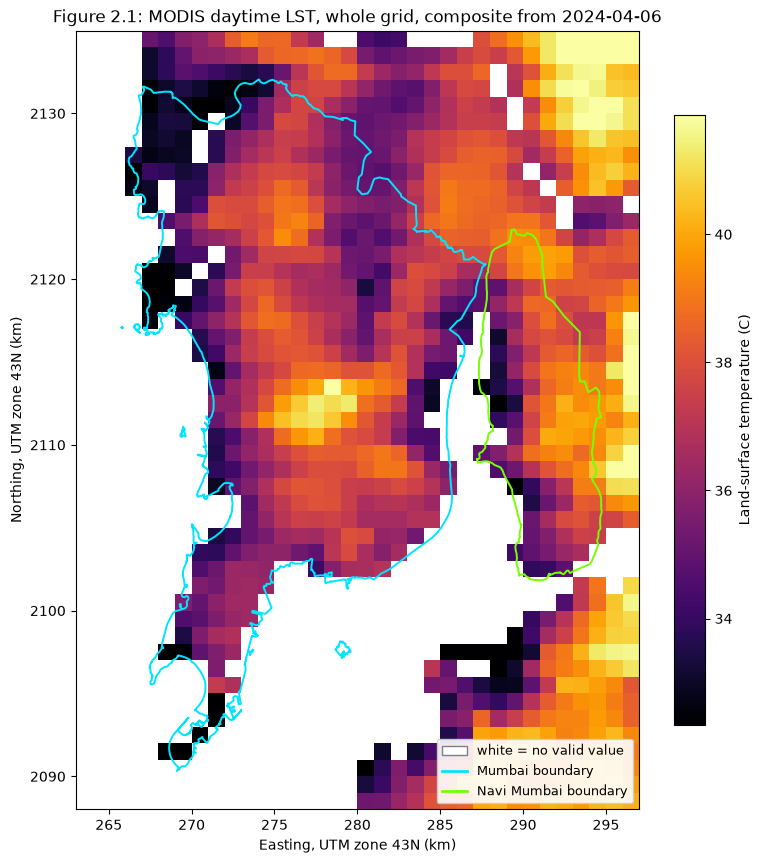

colour scale 32.3-41.9 C (2nd-98th percentile of the grid); valid cells 1031 of 1598


In [4]:
from urban_heat import plotting as Pl
vmin, vmax = np.nanpercentile(lst, 2), np.nanpercentile(lst, 98)
fig, ax = Pl.raster_map(lst, g1km, cities, vmin=vmin, vmax=vmax, cbar_label='Land-surface temperature (C)',
                        title=f'Figure 2.1: MODIS daytime LST, whole grid, composite from {MILESTONE_DATE}')
Pl.save(fig, config.OUTPUTS / 'charts' / 'fig2_1_milestone_whole_grid.png'); plt.show()
print(f'colour scale {vmin:.1f}-{vmax:.1f} C (2nd-98th percentile of the grid); valid cells {np.isfinite(lst).sum()} of {lst.size}')

## Figures 2.2 and 2.3: Milestone map clipped to each city
**What they show:** the same temperatures, keeping only the 1 km cells inside each city boundary (plan milestone step 4). These are the maps saved as GeoTIFFs for the QGIS check.

**How to read them:** the printed numbers give each city's valid cells, minimum, median and maximum LST.

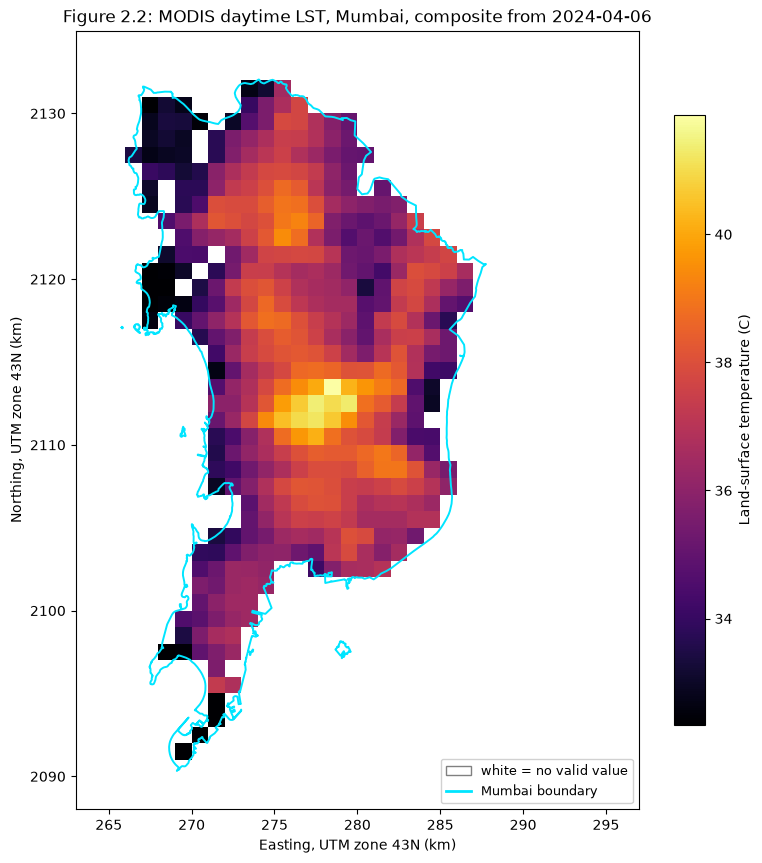

Mumbai: 449 of 470 cells valid; min 31.3 C, median 36.5 C, max 41.9 C


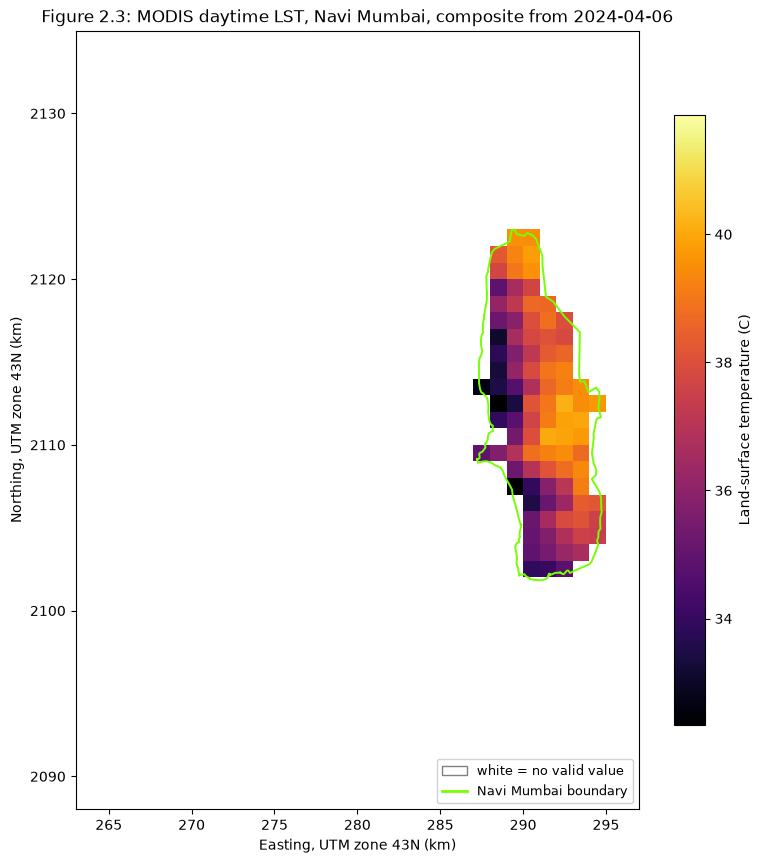

Navi Mumbai: 99 of 103 cells valid; min 32.3 C, median 37.7 C, max 40.2 C


In [5]:
for n, k in [(2, 'mumbai'), (3, 'navi_mumbai')]:
    fig, ax = Pl.raster_map(milestone[k], g1km, {k: cities[k]}, vmin=vmin, vmax=vmax, cbar_label='Land-surface temperature (C)',
                            title=f'Figure 2.{n}: MODIS daytime LST, {config.CITIES[k]}, composite from {MILESTONE_DATE}')
    Pl.save(fig, config.OUTPUTS / 'charts' / f'fig2_{n}_milestone_{k}.png'); plt.show()
    v = milestone[k][g1km.cell_mask(cities[k])]
    print(f'{config.CITIES[k]}: {np.isfinite(v).sum()} of {v.size} cells valid; min {np.nanmin(v):.1f} C, '
          f'median {np.nanmedian(v):.1f} C, max {np.nanmax(v):.1f} C')

## Figure 2.4: Why cells were kept or rejected (MODIS QC)
**What it shows:** the MODIS quality flag of every 1 km cell for this composite. Green = good quality; orange = "other quality" (LST produced, uncertain emissivity; kept when the LST error is <= 2 K); grey = LST not produced or error > 2 K (rejected); white = no MODIS value (sea).

**How to read it:** "other quality" covers most built-up cells. Keeping it (SRS assumption A4) is what makes the cities visible in Figures 2.2 and 2.3.

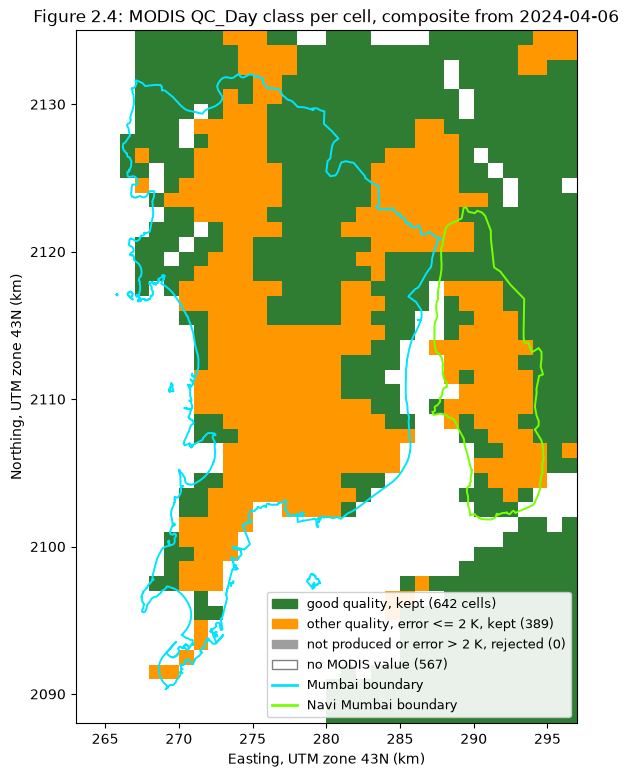

In [6]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
has = (dn >= modis_qc.VALID_DN[0])
m, e = modis_qc.mandatory_qa(qc), modis_qc.lst_error_class(qc)
cls = np.where(~has, np.nan, np.where((m == 0) & (e <= 1), 1, np.where((m == 1) & (e <= 1), 2, 3)))
fig, ax = plt.subplots(figsize=(8, 9))
ax.imshow(cls, extent=Pl.extent_km(g1km), cmap=ListedColormap(['#2e7d32', '#ff9800', '#9e9e9e']), vmin=1, vmax=3, interpolation='nearest')
count = lambda v: int(np.nansum(cls == v))
Pl.draw_cities(ax, cities, extra_handles=[
    Patch(color='#2e7d32', label=f'good quality, kept ({count(1)} cells)'),
    Patch(color='#ff9800', label=f'other quality, error <= 2 K, kept ({count(2)})'),
    Patch(color='#9e9e9e', label=f'not produced or error > 2 K, rejected ({count(3)})'),
    Patch(facecolor='white', edgecolor='grey', label=f'no MODIS value ({int((~has).sum())})')])
Pl.map_axes(ax, f'Figure 2.4: MODIS QC_Day class per cell, composite from {MILESTONE_DATE}')
Pl.save(fig, config.OUTPUTS / 'charts' / 'fig2_4_milestone_qc.png'); plt.show()

**Milestone check in QGIS:** add the OpenStreetMap basemap, then `outputs/historical_maps/milestone_lst_*.tif` and the boundaries from `data/boundaries/`. Each city's temperature cells should sit inside its outline, on land. April daytime land LST of roughly 30-45 C is sensible. Only then set `RUN_BULK = True`.

## Steps 1-2: MODIS MOD11A2 daytime LST + QC, 2001-2025

In [7]:
if RUN_BULK:
    print(acq.brief(acq.download_modis(ee, g1km, acq.modis_dates(config.START_YEAR, config.END_YEAR))))
else:
    print('RUN_BULK is off: skipped')

RUN_BULK is off: skipped


## Step 3: Landsat 8/9 for selected years
Selected years, months and the scene cloud limit are in `src/urban_heat/config.py` (`LANDSAT_YEARS`, `LANDSAT_MONTHS`, `LANDSAT_MAX_SCENE_CLOUD`). Each scene keeps its reflectance bands, thermal band and QA_PIXEL as delivered.

In [8]:
if RUN_BULK:
    print(acq.brief(acq.download_landsat(ee, g30, config.LANDSAT_YEARS)))
else:
    print('RUN_BULK is off: skipped')

RUN_BULK is off: skipped


## Step 4: WorldCover tiles covering both regions (10 m, 2020 and 2021)

In [9]:
factor = int(round(g30.res / config.WORLDCOVER_RES_M))
g10 = Grid(g30.crs, g30.xmin, g30.ymax, config.WORLDCOVER_RES_M, g30.width * factor, g30.height * factor)
if RUN_BULK:
    print(acq.brief(acq.download_worldcover(ee, g10)))
else:
    print('RUN_BULK is off: skipped')

RUN_BULK is off: skipped


## Step 5: ERA5-Land weather, same region and period
Daily values at ERA5-Land's native 0.1 degree cells (about 9 km) over the study area: 2 m temperature, dewpoint, skin temperature, 10 m wind. One CSV per year.

In [10]:
g_ll = acq.era5_grid(b.load(config.BOUNDARIES / 'combined_study_area.geojson').bounds)
print('ERA5-Land cells:', g_ll.width, 'x', g_ll.height, 'at', g_ll.res, 'deg')
if RUN_BULK:
    print(acq.brief(acq.download_era5(ee, g_ll, range(config.START_YEAR, config.END_YEAR + 1))))
else:
    print('RUN_BULK is off: skipped')

ERA5-Land cells: 3 x 5 at 0.1 deg
RUN_BULK is off: skipped


## Steps 6-7: Raw files and the catalogue

In [11]:
import pandas as pd
cat = pd.read_csv(config.CATALOG)
print(cat.groupby('dataset').agg(files=('file_path', 'count'), first=('date', 'min'), last=('date', 'max')))
for sub in ('modis', 'landsat', 'worldcover', 'era5'):
    files = list((config.RAW / sub).glob('*'))
    print(f'data/raw/{sub}: {len(files)} files, {sum(f.stat().st_size for f in files) / 1e6:.1f} MB')
per_year = cat[cat.dataset == 'MOD11A2'].date.str[:4].value_counts().sort_index()
print('MODIS composites per year (46 expected):', dict(per_year))

                 files       first        last
dataset                                       
ERA5-Land daily     25        2001        2025
ESA WorldCover       2        2020        2021
Landsat C2 L2      108  2014-03-11  2025-05-12
MOD11A2           1149  2001-01-01  2025-12-27
data/raw/modis: 1149 files, 3.0 MB
data/raw/landsat: 108 files, 908.4 MB
data/raw/worldcover: 2 files, 2.9 MB
data/raw/era5: 25 files, 11.8 MB
MODIS composites per year (46 expected): {'2001': np.int64(45), '2002': np.int64(46), '2003': np.int64(46), '2004': np.int64(46), '2005': np.int64(46), '2006': np.int64(46), '2007': np.int64(46), '2008': np.int64(46), '2009': np.int64(46), '2010': np.int64(46), '2011': np.int64(46), '2012': np.int64(46), '2013': np.int64(46), '2014': np.int64(46), '2015': np.int64(46), '2016': np.int64(46), '2017': np.int64(46), '2018': np.int64(46), '2019': np.int64(46), '2020': np.int64(46), '2021': np.int64(46), '2022': np.int64(46), '2023': np.int64(46), '2024': np.int64(46), '2025